# Local Stochastic Volatility (LSV) model on the CAC40

The Heston model of `heston_test.ipynb` reproduces the CAC40 surface within 0.42 vol point, and two parameter sets with
the same fit can give different exotic prices. The **LSV** model reprices the whole vanilla surface by construction and
keeps a stochastic volatility for the dynamics:
$$
\frac{dS_t}{S_t} = \mu(t)\,dt + L(t, S_t)\sqrt{v_t}\, dW^S_t, \qquad
dv_t = \kappa(\theta - v_t)\,dt + \eta\,\xi\sqrt{v_t}\, dW^v_t, \qquad d\langle W^S, W^v\rangle_t = \rho\,dt .
$$
By Gyöngy's theorem, the model has the vanilla prices of the Dupire local volatility $\sigma_{loc}$ if and only if
$$
L^2(t, K)\; \mathbb{E}[v_t \mid S_t = K] = \sigma_{loc}^2(t, K).
$$
- $(v_0, \theta, \kappa, \xi, \rho)$: the calibrated Heston parameters;
- $\eta \in [0, 1]$ (**mixing fraction**): $\eta = 0$ gives a deterministic variance, i.e. the pure **local volatility**
  model; $\eta = 1$ keeps the full Heston vol-of-vol. Every $\eta$ reprices the same vanillas: $\eta$ only changes the
  dynamics, hence the prices of path-dependent products.

**Pipeline**
1. Market implied surface, smoothed by SSVI (arbitrage-free) or SVI.
2. Dupire local volatility.
3. Pure local volatility model ($\eta = 0$).
4. LSV: leverage function calibrated by the particle method of Guyon & Henry-Labordère.
5. Repricing of the market surface: Heston vs local vol vs LSV.
6. Numerical convergence.
7. Model risk: exotic prices (barriers, Athena, Phoenix) as functions of $\eta$, at identical vanilla prices.
8. Greeks.

Implementation: `local_vol.py` (`LocalVolSurface`, `LSVModel`, `reprice_surface`).

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "Produits")))   # products.py, market.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market import cac40_heston
from local_vol import LocalVolSurface, LSVModel, reprice_surface
from products import VanillaOption, BarrierOption, DigitalBarrierOption, Athena, Phoenix
from monte_carlo import MonteCarloPricer
from greeks import Greeks

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 1. Market implied surface

The CAC40 surface of 12/02/2025 (142 quotes, 13 expiries) and the calibrated Heston model. Dupire's formula needs a
surface that is smooth in strike and maturity and free of arbitrage: the quotes are fitted by SSVI (Gatheral &
Jacquier, arbitrage-free by construction, 3 parameters) and by SVI (one smile per expiry, 5 parameters each).

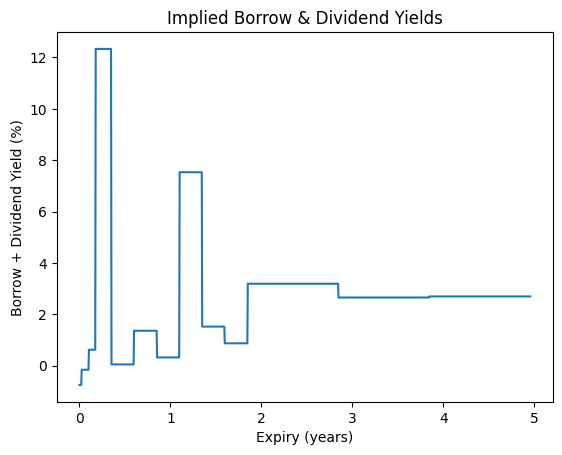

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


SSVI : rho = -0.4536, eta = 1.3759, gamma = 0.4177, RMSE = 0.218 vol pts
SVI  : RMSE by expiry from 0.003 to 0.079 vol pts


In [2]:
mkt = cac40_heston()
iv = mkt.iv_surface
ssvi_fit = iv.fit_ssvi(verbose=False)
svi_fit = iv.fit_svi(verbose=False)
local_ssvi = LocalVolSurface.from_ssvi(iv)
local_svi = LocalVolSurface.from_svi(iv)
print(f"SSVI : rho = {ssvi_fit['rho']:.4f}, eta = {ssvi_fit['eta']:.4f}, gamma = {ssvi_fit['gamma']:.4f}, RMSE = {ssvi_fit['RMSE (vol pts)']:.3f} vol pts")
print(f"SVI  : RMSE by expiry from {svi_fit['RMSE (vol pts)'].min():.3f} to {svi_fit['RMSE (vol pts)'].max():.3f} vol pts")

## 2. Dupire local volatility

In forward log-moneyness $y = \ln(K / F(0,T))$ and total implied variance $w(y, T) = \sigma_{imp}^2 T$ (Gatheral):
$$
\sigma_{loc}^2(T, y) = \frac{\partial_T w}{1 - \frac{y}{w}\partial_y w + \frac14\left(-\frac14 - \frac1w + \frac{y^2}{w^2}\right)(\partial_y w)^2 + \frac12 \partial_{yy} w}.
$$
The derivatives are finite differences of the fitted surface. Rates and dividends only enter through the forward.

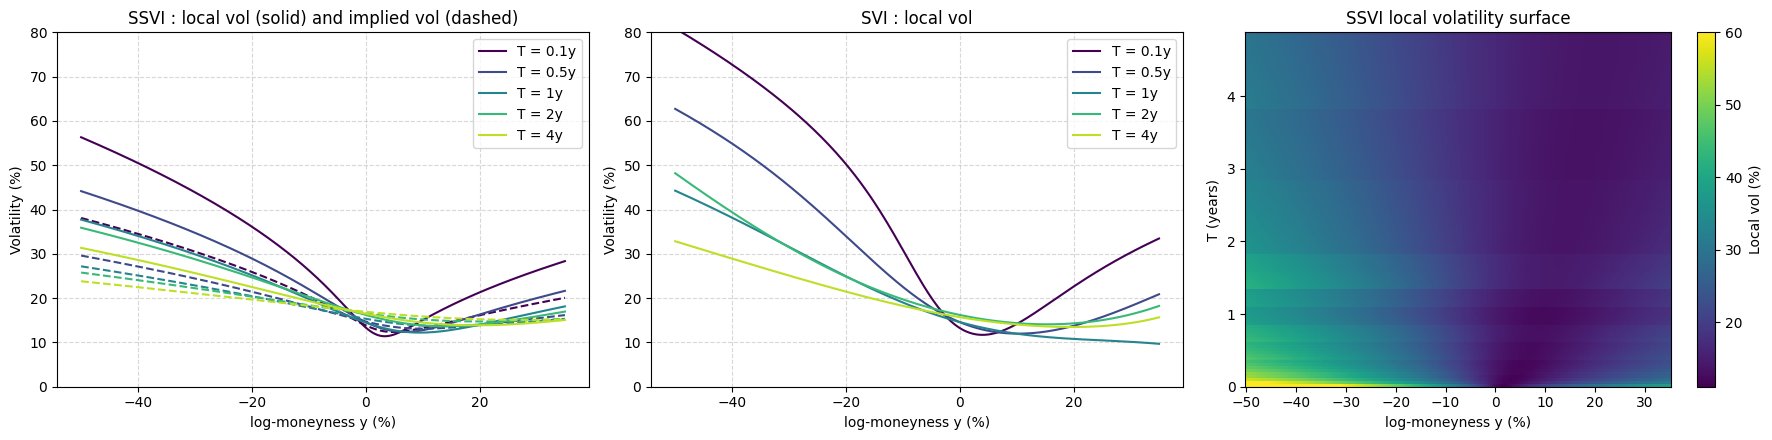

y (%),-30,-20,-10,0,10,20
T,,,,,,
0.1,43.9,36.13,26.29,13.36,15.04,21.29
0.5,34.74,28.95,22.02,14.61,12.76,16.3
1,29.89,25.16,19.78,14.47,12.22,13.99
2,28.79,24.68,20.29,16.21,13.84,14.08
4,25.65,22.52,19.35,16.48,14.49,13.86


In [3]:
ys = np.linspace(-0.5, 0.35, 200)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for T, color in zip([0.1, 0.5, 1.0, 2.0, 4.0], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    axes[0].plot(100 * ys, 100 * local_ssvi.implied_vol(ys, T), color=color, linestyle="--")
    axes[0].plot(100 * ys, 100 * local_ssvi.local_vol(ys, T), color=color, label=f"T = {T:g}y")
    axes[1].plot(100 * ys, 100 * local_svi.local_vol(ys, T), color=color, label=f"T = {T:g}y")
axes[0].set_title("SSVI : local vol (solid) and implied vol (dashed)")
axes[1].set_title("SVI : local vol")
for ax in axes[:2]:
    ax.set_xlabel("log-moneyness y (%)"); ax.set_ylabel("Volatility (%)"); ax.set_ylim(0, 80)
    ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
times = np.linspace(0.02, 4.86, 120)
grid = local_ssvi.grid(times, ys)
im = axes[2].pcolormesh(100 * ys, times, 100 * grid, cmap="viridis", vmax=60, shading="auto")
fig.colorbar(im, ax=axes[2], label="Local vol (%)")
axes[2].set_xlabel("log-moneyness y (%)"); axes[2].set_ylabel("T (years)"); axes[2].set_title("SSVI local volatility surface")
plt.tight_layout(); plt.show()
pd.DataFrame(100 * local_ssvi.grid([0.1, 0.5, 1, 2, 4], np.array([-0.3, -0.2, -0.1, 0.0, 0.1, 0.2])),
             index=pd.Index([0.1, 0.5, 1, 2, 4], name="T"), columns=pd.Index([-30, -20, -10, 0, 10, 20], name="y (%)")).round(2)

The local volatility is about twice as skewed as the implied volatility (the classical "two times the skew" rule at
the money), and the short-dated wings explode. SVI gives a steeper short-dated local volatility but its slices are
less regular in maturity; **SSVI is used in the rest of the notebook**.

## 3. Pure local volatility model ($\eta = 0$)

With $\eta = 0$ the variance is deterministic, $\mathbb{E}[v_t \mid S_t] = v_t$, so that $L \sqrt{v} = \sigma_{loc}$:
no particle noise. The simulation runs in $y = \ln(S/F)$, $dy = -\frac12 \sigma^2 dt + \sigma dW$ (Euler steps:
weekly for the calibration, daily for the repricing),
so that $\mathbb{E}[S_t] = F(0,t)$ exactly.

In [4]:
T_max = max(iv.expiries)
start = time.time()
local_vol_model = LSVModel.from_heston(mkt.heston, local_ssvi, mixing=0.0).calibrate(t_max=T_max, n_particles=50_000)
lv_repricing = reprice_surface(local_vol_model, iv, n_paths=100_000, target=local_ssvi)
lv_repricing["error vs market (pts)"] = 100 * (lv_repricing["model vol"] - lv_repricing["market vol"])
lv_repricing["error vs SSVI (pts)"] = 100 * (lv_repricing["model vol"] - lv_repricing["target vol"])
print(f"{time.time() - start:.1f}s")
rmse = lambda e: np.sqrt(np.nanmean(e**2))
lv_repricing.groupby("expiry")[["error vs market (pts)", "error vs SSVI (pts)"]].agg(rmse).T.round(3)

LSV leverage calibrated (mixing 0) : 253 steps, 50,000 particles, 0.6s


7.2s


expiry,0.0246575,0.10137,0.178082,0.350685,0.6,0.849315,1.09863,1.34795,1.59726,1.84658,2.84384,3.8411,4.85753
error vs market (pts),0.138,0.216,0.214,0.187,0.203,0.137,0.217,0.339,0.11,0.119,0.225,0.43,0.237
error vs SSVI (pts),0.221,0.128,0.189,0.168,0.2,0.131,0.07,0.04,0.021,0.038,0.034,0.015,0.018


The **error vs SSVI** is the numerical error of the model (Dupire finite differences, Euler steps, Monte Carlo);
the **error vs market** adds the SSVI fit error (0.22 vol point).

## 4. LSV : calibration of the leverage function

**Particle method** (Guyon & Henry-Labordère 2012). $N$ particles $(y, v)$ are simulated on the weekly grid. At each step:
1. $\mathbb{E}[v_t \mid y_t = y]$ is estimated on a grid of 60 points (quantiles 0.05%-99.95% of the particles) by a
   Gaussian kernel regression (Nadaraya-Watson) of bandwidth $h = 1.5\,\mathrm{std}(y)\,N^{-1/5}$;
2. $L(t, y) = \sigma_{loc}(t, y) / \sqrt{\mathbb{E}[v_t \mid y]}$;
3. the particles move one step with this leverage.

The pricing paths are then simulated independently with the calibrated $L$.

LSV leverage calibrated (mixing 1) : 253 steps, 50,000 particles, 13.2s


LSV leverage calibrated (mixing 0.5) : 253 steps, 50,000 particles, 12.8s
LSVModel(mixing=1, v0=0.0197, theta=0.0438, kappa=1.308, xi=0.482, rho=-0.605, surface=Dupire (SSVI))


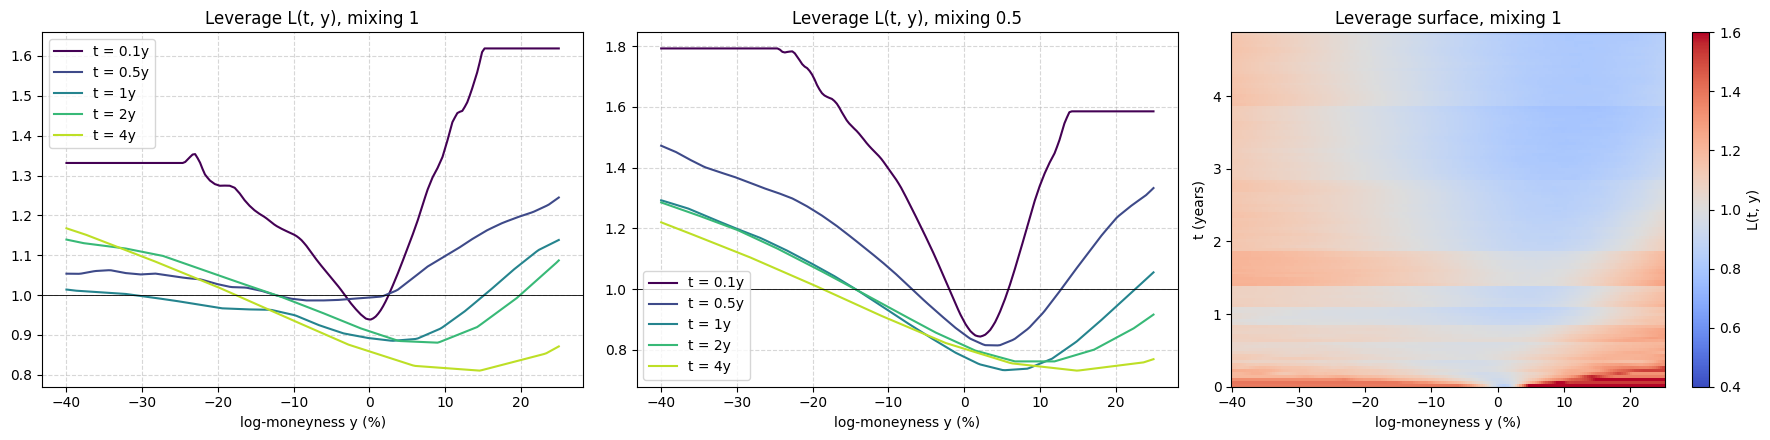

In [5]:
start = time.time()
lsv = LSVModel.from_heston(mkt.heston, local_ssvi, mixing=1.0).calibrate(t_max=T_max, n_particles=50_000)
lsv_half = LSVModel.from_heston(mkt.heston, local_ssvi, mixing=0.5).calibrate(t_max=T_max, n_particles=50_000)
print(lsv)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
y_plot = np.linspace(-0.4, 0.25, 200)
for T, color in zip([0.1, 0.5, 1.0, 2.0, 4.0], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    axes[0].plot(100 * y_plot, lsv.leverage(T, y_plot), color=color, label=f"t = {T:g}y")
    axes[1].plot(100 * y_plot, lsv_half.leverage(T, y_plot), color=color, label=f"t = {T:g}y")
for ax, title in zip(axes[:2], ["Leverage L(t, y), mixing 1", "Leverage L(t, y), mixing 0.5"]):
    ax.axhline(1, color="black", linewidth=0.6); ax.set_title(title); ax.set_xlabel("log-moneyness y (%)")
    ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
times = np.linspace(0.02, T_max, 120)
im = axes[2].pcolormesh(100 * y_plot, times, np.array([lsv.leverage(t, y_plot) for t in times]), cmap="coolwarm", vmin=0.4, vmax=1.6, shading="auto")
fig.colorbar(im, ax=axes[2], label="L(t, y)")
axes[2].set_xlabel("log-moneyness y (%)"); axes[2].set_ylabel("t (years)"); axes[2].set_title("Leverage surface, mixing 1")
plt.tight_layout(); plt.show()

With the full Heston dynamics, the leverage stays close to 1 around the money: the calibrated Heston model already
explains most of the surface, and $L$ only corrects its residual errors (the short-dated skew and the long-dated wings).

**Gyöngy check.** On fresh pricing paths, the conditional expectation of the instantaneous variance of the spot,
$\mathbb{E}[L^2 v_t \mid y_t = y]$, must equal $\sigma^2_{loc}(t, y)$.

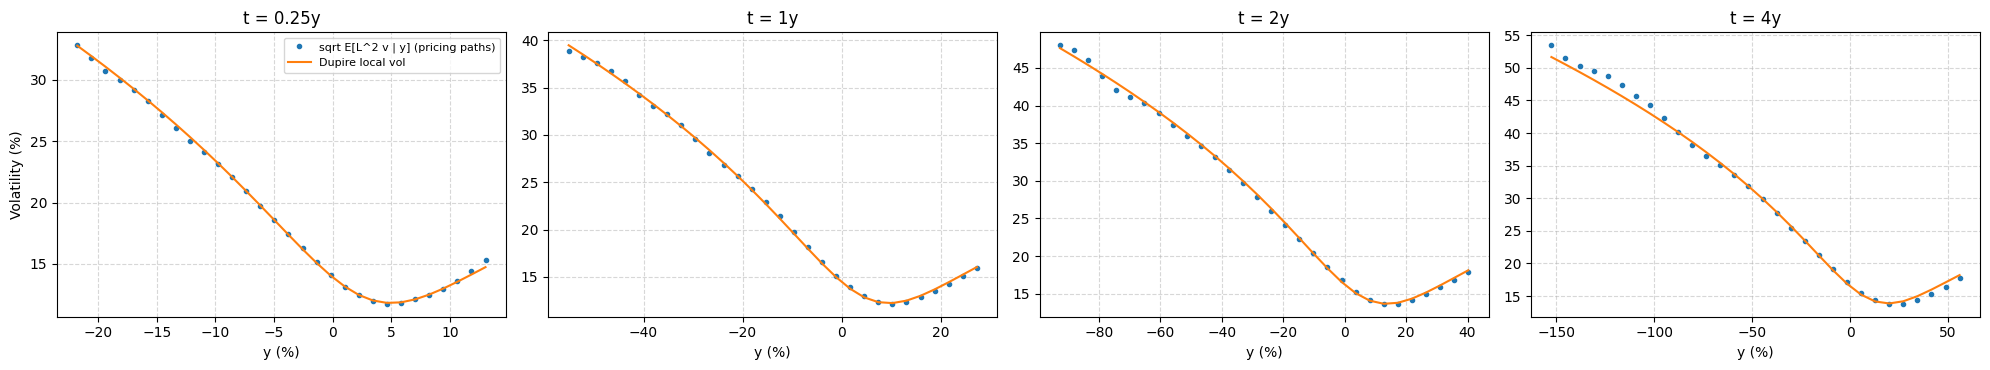

,t = 0.25y,t = 1y,t = 2y,t = 4y
max abs error (vol pts),0.604323,0.58487,0.92856,1.8053


In [6]:
S, V = lsv.generate_paths(T_max, int(round(T_max * 52)), 100_000, seed=11, antithetic=True)
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
rows = {}
for ax, t in zip(axes, [0.25, 1.0, 2.0, 4.0]):
    i = int(round(t * 52))
    y = np.log(S[i] / lsv.forward_price(i / 52))
    grid = np.linspace(*np.quantile(y, [0.02, 0.98]), 30)
    h = 1.5 * np.std(y) * len(y)**(-0.2)
    w = np.exp(-0.5 * ((y[:, None] - grid[None, :]) / h)**2)
    conditional = (w * V[i][:, None]).sum(0) / w.sum(0)
    target = local_ssvi.local_variance(grid, i / 52)
    ax.plot(100 * grid, 100 * np.sqrt(conditional), "o", markersize=3, label="sqrt E[L^2 v | y] (pricing paths)")
    ax.plot(100 * grid, 100 * np.sqrt(target), label="Dupire local vol")
    ax.set_title(f"t = {t:g}y"); ax.set_xlabel("y (%)"); ax.grid(True, linestyle="--", alpha=0.5)
    rows[f"t = {t:g}y"] = {"max abs error (vol pts)": 100 * np.max(np.abs(np.sqrt(conditional) - np.sqrt(target)))}
axes[0].set_ylabel("Volatility (%)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(rows)

## 5. Repricing of the market surface

Implied volatilities of the market quotes under the calibrated Heston model, the local volatility model and the LSV
model (100,000 paths, daily steps: the 9-day expiry needs several steps for the smile to build up).

In [7]:
start = time.time()
repricing = {"Heston": reprice_surface(mkt.heston, iv, n_paths=100_000),
             "Local vol (mixing 0)": lv_repricing,
             "LSV (mixing 0.5)": reprice_surface(lsv_half, iv, n_paths=100_000),
             "LSV (mixing 1)": reprice_surface(lsv, iv, n_paths=100_000)}
print(f"{time.time() - start:.1f}s")
by_expiry = pd.DataFrame({name: (100 * (r["model vol"] - r["market vol"])).groupby(r["expiry"]).apply(rmse)
                          for name, r in repricing.items()})
by_expiry.loc["All quotes"] = [rmse(100 * (r["model vol"] - r["market vol"])) for r in repricing.values()]
by_expiry.index = [f"{x:.3f}" if isinstance(x, float) else x for x in by_expiry.index]
by_expiry.round(3)

15.8s


,Heston,Local vol (mixing 0),LSV (mixing 0.5),LSV (mixing 1)
0.025,0.681,0.138,0.263,0.414
0.101,0.132,0.216,0.239,0.231
0.178,0.122,0.214,0.239,0.179
0.351,0.175,0.187,0.193,0.083
0.600,0.161,0.203,0.216,0.119
0.849,0.227,0.137,0.168,0.076
1.099,0.097,0.217,0.217,0.187
1.348,0.21,0.339,0.331,0.334
1.597,0.206,0.11,0.129,0.113
1.847,0.248,0.119,0.13,0.14


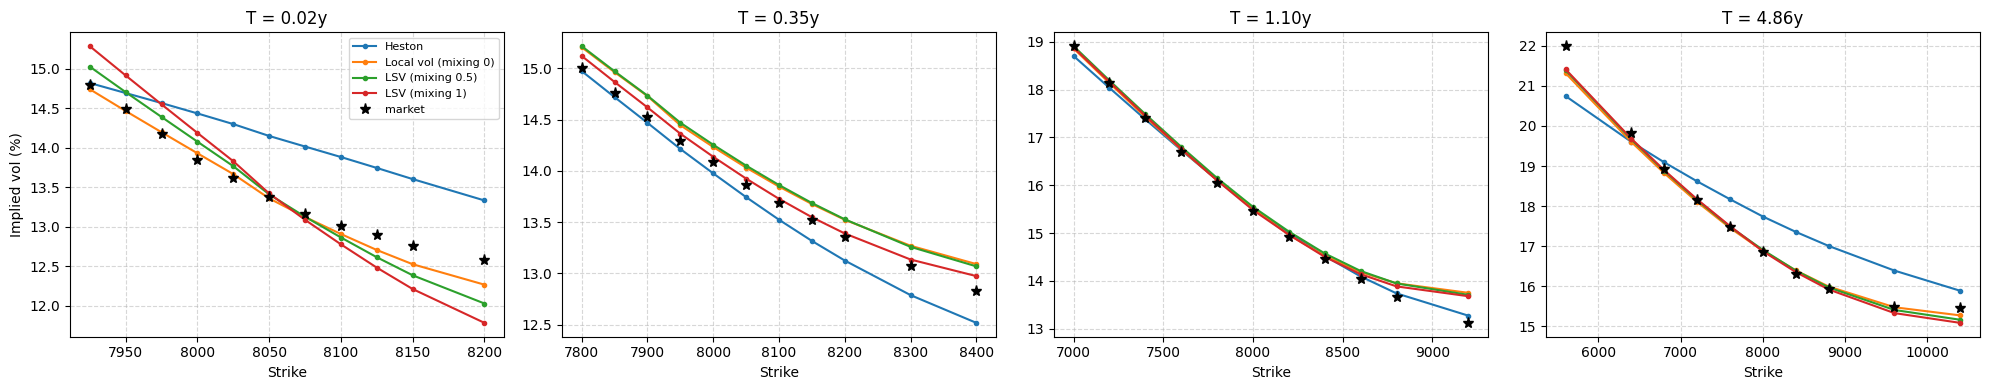

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, k in zip(axes, [0, 3, 6, 12]):
    T = iv.expiries[k]
    for name, r in repricing.items():
        d = r[r["expiry"] == T]
        ax.plot(d["strike"], 100 * d["model vol"], marker="o", markersize=3, label=name)
    ax.plot(iv.strikes[T], 100 * np.array(iv.implied_vols[T]), "k*", markersize=8, label="market")
    ax.set_title(f"T = {T:.2f}y"); ax.set_xlabel("Strike"); ax.grid(True, linestyle="--", alpha=0.5)
axes[0].set_ylabel("Implied vol (%)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Numerical convergence

Calibration time and repricing error of the LSV model (mixing 1) as functions of the number of particles.

In [9]:
rows = {}
for n in [10_000, 25_000, 50_000, 100_000]:
    model = LSVModel.from_heston(mkt.heston, local_ssvi, mixing=1.0).calibrate(t_max=T_max, n_particles=n, verbose=False)
    r = reprice_surface(model, iv, n_paths=100_000, target=local_ssvi)
    rows[f"{n:,}"] = {"calibration time (s)": model.calibration_time,
                      "RMSE vs SSVI (vol pts)": rmse(100 * (r["model vol"] - r["target vol"])),
                      "RMSE vs market (vol pts)": rmse(100 * (r["model vol"] - r["market vol"]))}
convergence = pd.DataFrame(rows).T
convergence.index.name = "particles"
convergence.round(3)

,calibration time (s),RMSE vs SSVI (vol pts),RMSE vs market (vol pts)
particles,,,
"10,000",2.292,0.147,0.251
"25,000",6.314,0.108,0.246
"50,000",13.03,0.088,0.245
"100,000",26.547,0.083,0.242


## 7. Model risk : exotic prices at identical vanilla prices

All the LSV models reprice the same vanillas; the mixing fraction only changes the dynamics of the volatility.
Products: 1-year European options (strike 8000, continuous barriers, daily steps) and the 4-year notes of
`Produits/Athena` and `Produits/Phoenix` (weekly steps). 50,000 paths, no control variate (it is not available for
the local volatility models), common seed.

In [10]:
mixings = [0.0, 0.25, 0.5, 0.75, 1.0]
start = time.time()
models = {"Heston": mkt.heston}
for eta in mixings:
    models[f"LSV {eta:g}"] = LSVModel.from_heston(mkt.heston, local_ssvi, mixing=eta).calibrate(t_max=T_max, n_particles=50_000, verbose=False)
S0 = mkt.S0
options = {"Put 1y ATM (vanilla)": VanillaOption(8000, 1.0, False), "Call 1y ATM (vanilla)": VanillaOption(8000, 1.0, True),
           "PDO 1y, H 7200": BarrierOption.from_code("PDO", 8000, 7200, 1.0), "PDI 1y, H 7200": BarrierOption.from_code("PDI", 8000, 7200, 1.0),
           "CDO 1y, H 7200": BarrierOption.from_code("CDO", 8000, 7200, 1.0), "CUO 1y, H 8800": BarrierOption.from_code("CUO", 8000, 8800, 1.0),
           "Down-and-out digital 1y (100), H 7200": DigitalBarrierOption(8000, 1.0, 7200, True, "down", "out", cash=100)}
notes = {"Athena 4y, EU 60%": Athena(4.0, S0, 0.08, frequency=1.0),
         "Athena 4y, AM 60%": Athena(4.0, S0, 0.08, frequency=1.0, protection_type="american"),
         "Phoenix 4y, CB 70%": Phoenix(4.0, S0, 0.06, coupon_barrier=0.7, frequency=0.25)}
prices, errors = {}, {}
for name, model in models.items():
    daily = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42, control_variate=False)
    weekly = MonteCarloPricer(n_paths=50_000, steps_per_year=52, seed=42, control_variate=False)
    prices[name], errors[name] = {}, {}
    for label, p in options.items():
        r = daily.price(model, p); prices[name][label], errors[name][label] = r.price, r.stderr
    for label, n in notes.items():
        r = weekly.price(model, n); prices[name][label], errors[name][label] = r.price, r.stderr
        prices[name][label + " : fair coupon (%)"] = 100 * n.fair_coupon(weekly, model)
print(f"{time.time() - start:.1f}s")
model_risk = pd.DataFrame(prices)
model_risk["LSV range (max - min)"] = model_risk[[f"LSV {e:g}" for e in mixings]].max(axis=1) - model_risk[[f"LSV {e:g}" for e in mixings]].min(axis=1)
model_risk["max std error"] = pd.DataFrame(errors).max(axis=1)
model_risk.round(3)

79.5s


,Heston,LSV 0,LSV 0.25,LSV 0.5,LSV 0.75,LSV 1,LSV range (max - min),max std error
Put 1y ATM (vanilla),467.828,470.816,471.824,472.467,472.439,470.616,1.851,3.364
Call 1y ATM (vanilla),491.029,495.689,496.5,496.726,496.144,494.277,2.449,2.529
"PDO 1y, H 7200",16.409,17.576,17.042,16.724,16.423,16.07,1.506,0.334
"PDI 1y, H 7200",451.42,453.239,454.782,455.743,456.016,454.545,2.777,3.417
"CDO 1y, H 7200",407.544,423.332,423.783,421.273,416.173,408.466,15.318,2.493
"CUO 1y, H 8800",63.042,34.577,37.175,44.279,54.739,64.728,30.152,0.671
"Down-and-out digital 1y (100), H 7200",44.437,42.897,42.915,43.097,43.595,44.2,1.302,0.167
"Athena 4y, EU 60%",98.57,98.181,98.241,98.334,98.366,98.469,0.287,0.097
"Athena 4y, EU 60% : fair coupon (%)",9.439,9.72,9.682,9.61,9.602,9.517,0.203,NaN
"Athena 4y, AM 60%",96.808,96.54,96.553,96.625,96.649,96.769,0.229,0.101


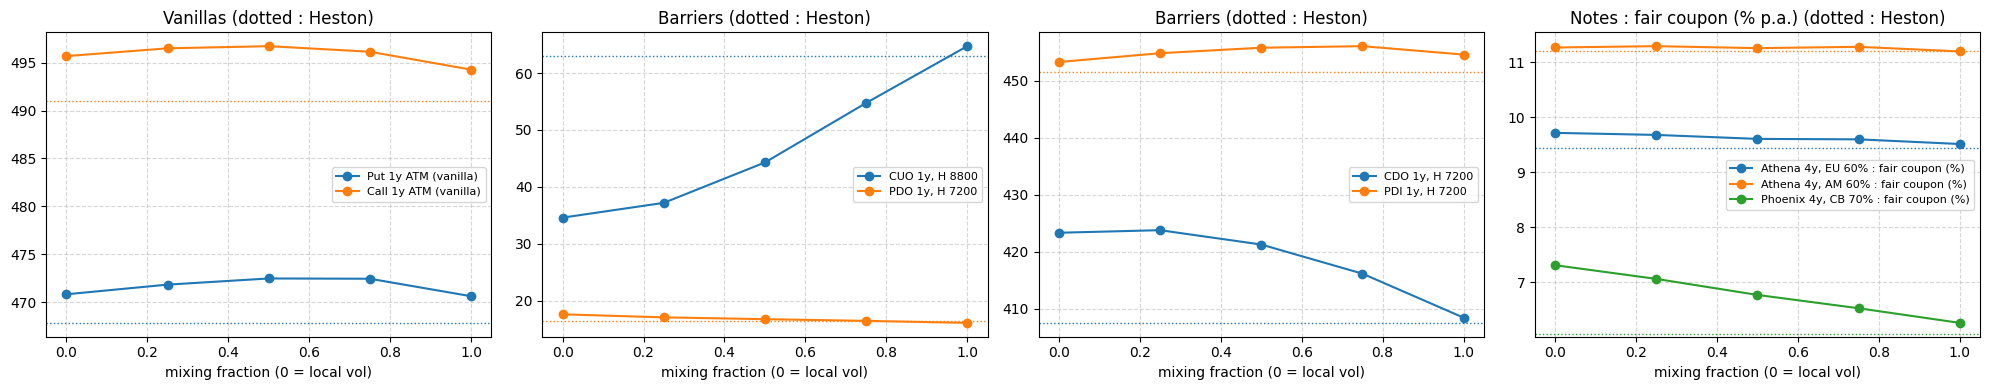

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, labels, title in zip(axes, [["Put 1y ATM (vanilla)", "Call 1y ATM (vanilla)"], ["CUO 1y, H 8800", "PDO 1y, H 7200"],
                                    ["CDO 1y, H 7200", "PDI 1y, H 7200"],
                                    ["Athena 4y, EU 60% : fair coupon (%)", "Athena 4y, AM 60% : fair coupon (%)", "Phoenix 4y, CB 70% : fair coupon (%)"]],
                             ["Vanillas", "Barriers", "Barriers", "Notes : fair coupon (% p.a.)"]):
    for label in labels:
        line, = ax.plot(mixings, [model_risk.loc[label, f"LSV {e:g}"] for e in mixings], "o-", label=label)
        ax.axhline(model_risk.loc[label, "Heston"], color=line.get_color(), linestyle=":", linewidth=1)
    ax.set_xlabel("mixing fraction (0 = local vol)"); ax.set_title(title + " (dotted : Heston)")
    ax.grid(True, linestyle="--", alpha=0.5); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Up-and-out call as a function of the barrier.** The up-and-out call is the most sensitive product: its value comes
from paths that rise towards the barrier without touching it, i.e. from the forward skew and the volatility of
volatility.

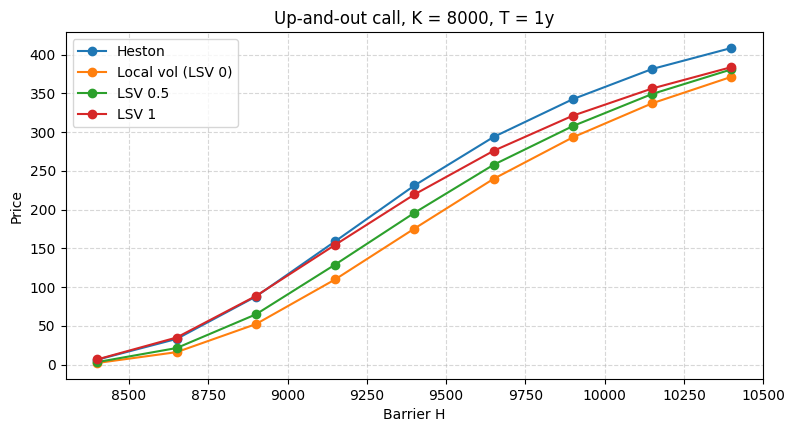

barrier,8400,8650,8900,9150,9400,9650,9900,10150,10400
Heston,6.32,33.08,87.76,158.98,231.04,293.7,342.48,381.37,408.48
LSV 0,2.06,16.03,52.19,109.84,175.44,239.67,293.27,337.11,371.28
LSV 0.5,3.23,21.33,64.76,129.01,195.79,257.84,307.76,349.15,380.86
LSV 1,6.69,34.9,88.45,154.47,219.48,275.84,321.16,356.22,383.78


In [12]:
barriers = np.arange(8400, 10401, 250)
fig, ax = plt.subplots(figsize=(9, 4.5))
cuo = {}
for name in ["Heston", "LSV 0", "LSV 0.5", "LSV 1"]:
    daily = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42, control_variate=False)
    cuo[name] = [daily.price(models[name], BarrierOption.from_code("CUO", 8000, H, 1.0)).price for H in barriers]
    ax.plot(barriers, cuo[name], "o-", label=name if name != "LSV 0" else "Local vol (LSV 0)")
ax.set_xlabel("Barrier H"); ax.set_ylabel("Price"); ax.set_title("Up-and-out call, K = 8000, T = 1y")
ax.grid(True, linestyle="--", alpha=0.5); ax.legend(); plt.show()
pd.DataFrame(cuo, index=pd.Index(barriers, name="barrier")).round(2).T

## 8. Greeks

Greeks of the up-and-out call and of the base Athena under the local volatility, LSV and Heston models (common random
numbers, 50,000 paths). For the LSV models, **Vega and Volga shift the whole implied surface by one vol point and
recalibrate the leverage**; for Heston they shift $\sqrt{v_0}$ and $\sqrt{\theta}$, so the two definitions differ.
Delta keeps the surface fixed in moneyness (sticky moneyness).

In [13]:
greek_list = ("delta", "gamma", "vega", "volga", "rho", "dividend", "theta")
start = time.time()
greek_tables = {}
for product_name, product, steps in [("CUO 1y, H 8800", options["CUO 1y, H 8800"], 252), ("Athena 4y, EU 60%", notes["Athena 4y, EU 60%"], 52)]:
    pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=steps, seed=42, control_variate=False)
    greek_tables[product_name] = pd.DataFrame({name: Greeks(pricer).compute(models[name], product, greek_list)["value"]
                                               for name in ["LSV 0", "LSV 0.5", "LSV 1", "Heston"]})
print(f"{time.time() - start:.1f}s")
pd.concat(greek_tables, axis=0).round(5)

167.8s


LSV 0  LSV 0.5    LSV 1   Heston
CUO 1y, H 8800    price     34.5768  44.2793  64.7283  63.0418
                  delta    -0.04571 -0.05473 -0.04909 -0.06184
                  gamma      -5e-05   -8e-05 -0.00023 -0.00021
                  vega     -6.04856 -7.02648 -7.93896 -11.4561
                  volga     1.45224  1.71364  1.15766  1.78597
                  rho      -1.23989 -1.52545 -1.97222 -1.44581
                  dividend  0.89417  1.08248  1.32543  0.81562
                  theta     0.10686  0.17296  0.18837   0.2097
Athena 4y, EU 60% price     98.1815  98.3337  98.4689  98.5696
                  delta     0.00481  0.00491  0.00496  0.00505
                  gamma      -1e-05   -1e-05   -1e-05       -0
                  vega     -0.57499 -0.55727 -0.52704 -0.53365
                  volga    -0.03513 -0.00184 -0.04489 -0.04024
                  rho      -0.74267 -0.80295 -0.74813 -0.77382
                  dividend  -1.0855 -1.03798 -1.11411 -1.11066
                  theta     0.00858  0.00632  0.00521  0.00488

## 9. Limitations

- Dupire depends on the smoothing of the quotes: the SSVI fit error (0.22 vol point) is inherited by every model.
- Particle method: kernel regression bias and noise, weekly time steps; the leverage is clipped where the local
  volatility is extreme (short-dated wings).
- The leverage is defined in forward moneyness: a spot bump moves the whole surface with the spot (sticky moneyness).
- The mixing fraction is not identified by vanillas: it must be calibrated to exotic prices (barrier or forward-start
  quotes), which are not available here.